# Coupling of absorption and scattering (1/3): what the hGRS transmittance assumes

hGRS corrects the gaseous absorption with **one transmittance per band for the whole TOA signal**,
computed for the direct beam along the two-way air mass $\bar M = 1/\mu_0 + 1/\mu_v$:

$$
R_{toa} = T_g(\bar M)\; T_{wv}(W, \bar M)\; \left[ R_{diff}(\tau_a) + R_{dir}\,BRDF_g + T^{\downarrow}t^{\uparrow} \pi R_{rs} \right]
$$

with $T_{wv} = \langle e^{-\bar M W \kappa_{H_2O}(\lambda)} \rangle_{band}$ (REPTRAN fine table) and, for the O2, O4 and CO2
background, $T_g = \langle e^{-\bar M \kappa\, (P/1000)\, \tau_{O_2+O_4+CO_2}} \rangle$ with an empirical factor
$\kappa$ = `gas_absorption_scattering_coefficient` = 0.35.

This is exact for the light that crosses the whole atmosphere twice along straight lines (direct sun glint, and nearly
for the water-leaving signal). It is not for the **path reflectance** $R_{diff}$: the photons scattered by the molecules
and aerosols above the absorbers shortcut part of the absorbing column, and their path lengths are spread. Over dark
water $R_{diff}$ is most of the TOA signal in the near infrared.

This notebook quantifies the difference with the **SOS-ABS** simulations (successive orders of scattering coupled with
correlated-k absorption, CKD 5 cm$^{-1}$; Lenoble et al., 2007) made for `radcalnet_oc`
(`scripts/sos_abs_coupling/make_luts.py`, set v2), at the resolution of the EnMAP bands:

1. check of the absorption data of hGRS (REPTRAN) against SOS-ABS on the direct beam;
2. transmittance of each term of the signal (path reflectance, surface term) against the direct beam;
3. dependence on the aerosol load, the solar angle and the water vapour column;
4. the TOA signal as a mixture of terms: the transmittance a decoupled model sees;
5. the photon path-length model of `radcalnet_oc` against the simulations.

Notebook 2 applies this to the water vapour retrieval, notebook 3 to the O2 bands.

## Simulations

The v2 set covers five absorption windows: O2-B (684-698 nm), H2O 720 (712-736 nm), O2-A (757-772 nm), H2O 820
(808-836 nm) and H2O 940 (890-990 nm), sampled every 0.5-1 nm (each sample is a 5 cm$^{-1}$ CKD interval), for
water vapour columns $U$ of 0.5, 2 and 4 g cm$^{-2}$ (5-40 kg m$^{-2}$), solar zenith angles of 20-70°, AOT(550) of
0.05-0.4 (WMO maritime model), and a rough sea surface (Cox-Munk, 5 m s$^{-1}$) with a Lambertian water albedo of
0, 0.03 or 0.1. The same fields are computed without absorption (`noabs.nc`), and the direct beam with and without
absorption as a function of the air mass (`tgdir_*.nc`). The decomposition used below:

* **path term** (albedo 0, black water): atmosphere + reflection of the sky and of the sun by the sea surface;
  $T_{path} = R^{abs}_{toa}(0) / R^{noabs}_{toa}(0)$;
* **surface term**: $T_{surf} = \Delta R^{abs} / \Delta R^{noabs}$ with $\Delta R = R_{toa}(0.1) - R_{toa}(0)$;
* **direct beam**: $T_{dir}(m)$ = ratio of the direct fluxes, at the two-way air mass $m$.

The geometry is that of the EnMAP test scene of the next notebooks (Lucinda, 2026-05-31): $\theta_s$ = 44.5°,
$\theta_v$ = 15.9°, relative azimuth 90° (out of the sun glint).

In [1]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import coupling_tools as ct

warnings.filterwarnings('ignore')
ct.set_style()
pd.set_option('display.precision', 3)

sos_abs, sos_noabs, tgdir_abs, tgdir_noabs = ct.load_sos()
bands = ct.Bands.enmap_lucinda()
SZA, VZA, AZI = 44.5, 15.9, 90.
M = ct.air_mass(SZA, VZA)
print(f'two-way air mass m = {M:.3f}')
print('EnMAP bands inside the sampled windows:', {k: list(np.round(v, 1)) for k, v in bands.in_windows().items()})

two-way air mass m = 2.442
EnMAP bands inside the sampled windows: {'H2O-720': [np.float64(720.5), np.float64(727.5)], 'H2O-820': [np.float64(816.6), np.float64(824.4)], 'H2O-940': [np.float64(931.2), np.float64(941.2), np.float64(951.4), np.float64(961.6), np.float64(972.0)]}


The O2 windows are narrower than an EnMAP band and its wings: they are handled in notebook 3, with the transmittance
set to 1 outside the windows. Here, the bands of the H2O windows (EnMAP has no band between 888 and 931 nm on this
product: the VNIR/SWIR overlap is removed by the reader).

## 1. Direct beam: absorption data of hGRS against SOS-ABS

In [2]:
gas = ct.gas_lut(700, 1000)
rows = []
for U in (0.5, 2., 4.):
    t_sos = bands.convolve_windows(ct.tg_direct(tgdir_abs, tgdir_noabs, M, U))
    t_hgrs = bands.average(ct.hgrs_twv(M, U * 10, gas), gas.wl.values, t_sos.wl.values)
    for w, a, h in zip(t_sos.wl.values, t_sos.values, t_hgrs):
        rows.append(dict(U_gcm2=U, band_nm=round(w, 1), T_SOS=a, T_hGRS_REPTRAN=h, ratio=h / a))
direct = pd.DataFrame(rows)
direct.pivot(index='band_nm', columns='U_gcm2', values='ratio').rename_axis(columns='U (g cm-2): T_hGRS / T_SOS')

U (g cm-2): T_hGRS / T_SOS,0.5,2.0,4.0
band_nm,,,
720.5,0.974,0.939,0.930
727.5,0.996,0.962,0.937
816.6,0.985,0.936,0.911
824.4,0.972,0.918,0.896
931.2,0.896,0.846,0.824
941.2,0.948,0.929,0.934
951.4,0.945,0.930,0.961
961.6,0.943,0.867,0.865
972.0,0.965,0.933,0.927


Along the direct beam, the REPTRAN water vapour absorption of hGRS is stronger than the CKD of SOS-ABS:
$T_{hGRS}/T_{SOS}$ = 0.85-0.96 for 2 g cm$^{-2}$ and 0.82-0.96 for 4 g cm$^{-2}$ (0.90-1.00 for 0.5 g cm$^{-2}$), the
largest difference at 931 nm. This database difference is kept apart in notebook 2 (retrieval with a transmittance
consistent with SOS-ABS); it is smaller than the coupling effect below.

## 2. Transmittance of each term

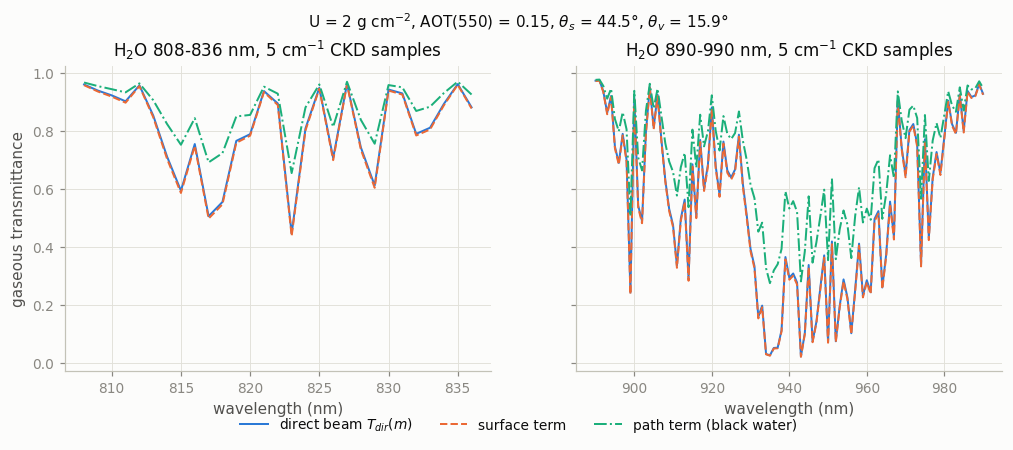

In [3]:
def terms(U=2., aot=0.15, sza=SZA, vza=VZA, azi=AZI):
    """transmittances of the path term, of the surface term and of the direct beam (SOS-ABS wavelengths)"""
    a, n = sos_abs.sel(h2o=U), sos_noabs
    r0a, r0n = ct.toa(a, sza, vza, azi, albedo=0., aot_ref=aot), ct.toa(n, sza, vza, azi, albedo=0., aot_ref=aot)
    r1a, r1n = ct.toa(a, sza, vza, azi, albedo=0.1, aot_ref=aot), ct.toa(n, sza, vza, azi, albedo=0.1, aot_ref=aot)
    m = ct.air_mass(sza, vza)
    return dict(path=r0a / r0n, surface=(r1a - r0a) / (r1n - r0n), direct=ct.tg_direct(tgdir_abs, tgdir_noabs, m, U),
                path_reflectance=r0n, surface_reflectance=r1n - r0n)

t = terms()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (lo, hi) in zip(axes, [(808, 836), (890, 990)]):
    for i, (k, lab) in enumerate([('direct', 'direct beam $T_{dir}(m)$'), ('surface', 'surface term'),
                                  ('path', 'path term (black water)')]):
        s = t[k].sel(wl=slice(lo, hi))
        ax.plot(s.wl, s, color=ct.COLORS[i], linestyle=ct.STYLES[i], lw=1.3, label=lab)
    ax.set_xlabel('wavelength (nm)')
    ax.set_title(f'H$_2$O {lo}-{hi} nm, 5 cm$^{{-1}}$ CKD samples')
axes[0].set_ylabel('gaseous transmittance')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f'U = 2 g cm$^{{-2}}$, AOT(550) = 0.15, $\\theta_s$ = {SZA}°, $\\theta_v$ = {VZA}°', y=1.02, fontsize=10)
plt.show()

In [4]:
def band_terms(**kw):
    t = terms(**kw)
    conv = bands.convolve_windows
    out = pd.DataFrame({'direct T(m)': conv(t['direct']).values,
                        'surface': (conv(t['surface'] * t['surface_reflectance']) / conv(t['surface_reflectance'])).values,
                        'path': (conv(t['path'] * t['path_reflectance']) / conv(t['path_reflectance'])).values},
                       index=pd.Index(np.round(conv(t['direct']).wl.values, 1), name='band (nm)'))
    out['path / direct'] = out['path'] / out['direct T(m)']
    return out

band_terms()

,direct T(m),surface,path,path / direct
band (nm),,,,
720.5,0.751,0.743,0.852,1.135
727.5,0.735,0.727,0.844,1.148
816.6,0.738,0.731,0.834,1.131
824.4,0.785,0.779,0.862,1.098
931.2,0.340,0.334,0.563,1.655
941.2,0.193,0.187,0.450,2.337
951.4,0.222,0.217,0.475,2.136
961.6,0.380,0.374,0.589,1.547
972.0,0.660,0.653,0.780,1.182


At band level (U = 2 g cm$^{-2}$, AOT 0.15):

* the **surface term** follows the direct beam closely (slightly lower: part of the irradiance is skylight, with longer
  paths through the absorbing layer);
* the **path term** is much less absorbed: its transmittance is 1.10-1.15 times that of the direct beam in the 720 and
  820 nm bands, and 1.2-2.3 times in the 940 nm band (2.3 at 941 nm).

In the band averages above, each transmittance is weighted by the reflectance of its term (band average of
$T R$ over band average of $R$), as a sensor measures it.

## 3. Dependence on the aerosol load, the solar angle and the water vapour

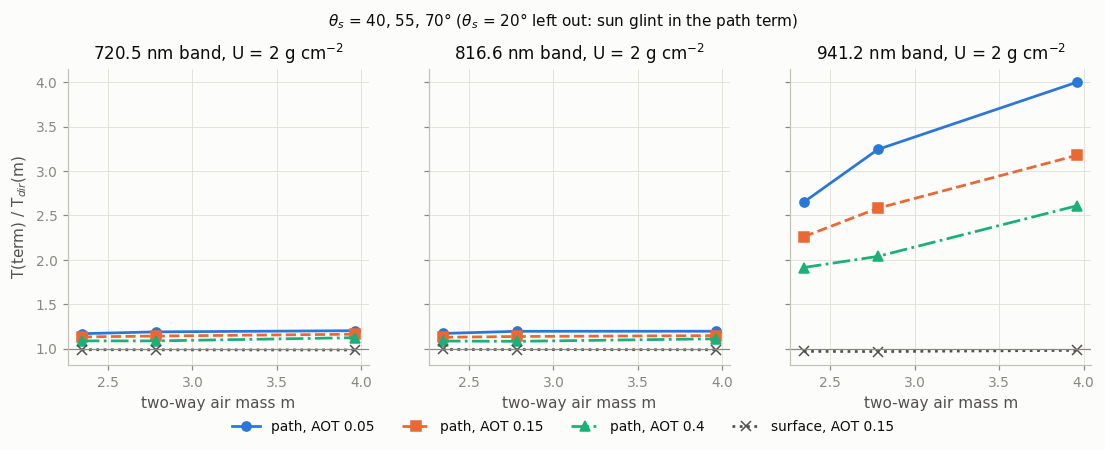

T_path at 941 nm, AOT:   0.05   0.15   0.40
U   sza                                    
0.5 20.0                0.573  0.589  0.610
    40.0                0.724  0.671  0.623
    55.0                0.723  0.644  0.580
    70.0                0.623  0.559  0.520
2.0 20.0                0.296  0.319  0.349
    40.0                0.533  0.454  0.385
    55.0                0.548  0.436  0.345
    70.0                0.445  0.353  0.290
4.0 20.0                0.179  0.201  0.230
    40.0                0.439  0.352  0.275
    55.0                0.465  0.344  0.246
    70.0                0.372  0.274  0.204

In [5]:
rows = []
for U in (0.5, 2., 4.):
    for aot in (0.05, 0.15, 0.4):
        for sza in (20., 40., 55., 70.):
            bt = band_terms(U=U, aot=aot, sza=sza)
            for w in (720.5, 816.6, 941.2):
                r = bt.loc[w]
                rows.append(dict(U=U, aot=aot, sza=sza, m=ct.air_mass(sza, VZA), band=w, direct=r['direct T(m)'],
                                 path=r['path'], surface=r['surface']))
dep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, w in zip(axes, (720.5, 816.6, 941.2)):
    for i, aot in enumerate((0.05, 0.15, 0.4)):
        s = dep[(dep.band == w) & (dep.U == 2.) & (dep.aot == aot) & (dep.sza > 20)]
        ax.plot(s.m, s.path / s.direct, **ct.series(i), label=f'path, AOT {aot}')
    s = dep[(dep.band == w) & (dep.U == 2.) & (dep.aot == 0.15) & (dep.sza > 20)]
    ax.plot(s.m, s.surface / s.direct, color=ct.INK2, linestyle=':', marker='x', label='surface, AOT 0.15')
    ax.axhline(1, color=ct.MUTED, lw=0.8)
    ax.set_title(f'{w} nm band, U = 2 g cm$^{{-2}}$')
    ax.set_xlabel('two-way air mass m')
axes[0].set_ylabel('T(term) / T$_{dir}$(m)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.1))
fig.suptitle('$\\theta_s$ = 40, 55, 70° ($\\theta_s$ = 20° left out: sun glint in the path term)', y=1.03, fontsize=10)
plt.show()
dep[(dep.band == 941.2)].pivot_table(index=['U', 'sza'], columns='aot', values='path').rename_axis(
    columns='T_path at 941 nm, AOT:')

The ratio of the path transmittance to the direct one grows with the air mass and with the absorption (from 720 to 940
nm, and with $U$), and decreases with the aerosol load: aerosols scatter lower in the atmosphere, closer to the water
vapour, so their photons cross more of it. For clean atmospheres (AOT 0.05), where the path reflectance is mostly
Rayleigh scattering high above the water vapour, the path term is the least absorbed. The surface term stays within a
few percent of the direct beam everywhere.

## 4. The TOA signal is a mixture: what a single transmittance sees

With a path reflectance $R_p$ (transmittance $T_p$) and a surface term $R_s$ (transmittance $\simeq T_{dir}$), the TOA
transmittance of the whole signal is $T_{toa} = (T_p R_p + T_{dir} R_s)/(R_p + R_s)$. A decoupled model, which assigns
$T_{dir}(W)$ to the whole signal, finds the water vapour column $W_{app}$ that gives $T_{dir}(W_{app}) = T_{toa}$:

In [6]:
def apparent_column(U=2., aot=0.15, sza=SZA, albedo=0., band=941.2):
    """column W_app (g cm-2) giving the observed band transmittance with the direct-beam model T_dir(m W)"""
    a, n = sos_abs.sel(h2o=U), sos_noabs
    ra, rn = ct.toa(a, sza, VZA, AZI, albedo=albedo, aot_ref=aot), ct.toa(n, sza, VZA, AZI, albedo=albedo, aot_ref=aot)
    conv = bands.convolve_windows
    t_toa = float((conv(ra) / conv(rn)).sel(wl=band, method='nearest'))
    m = ct.air_mass(sza, VZA)
    us = np.linspace(0., 8., 801)
    t_dir = direct_beam(m * us)[0]           # decreasing with W
    frac = float(conv(ct.toa(n, sza, VZA, AZI, albedo=0., aot_ref=aot)).sel(wl=band, method='nearest') /
                 conv(rn).sel(wl=band, method='nearest'))
    return np.interp(t_toa, t_dir[::-1], us[::-1]), frac, t_toa

direct_beam = ct.DirectBeam(tgdir_abs, tgdir_noabs, bands, [941.2])

rows = []
for albedo in (0., 0.03, 0.1):
    for aot in (0.05, 0.15, 0.4):
        w_app, frac, t_toa = apparent_column(albedo=albedo, aot=aot)
        rows.append(dict(albedo=albedo, aot=aot, path_fraction=frac, T_toa_941=t_toa, W_app_over_U=w_app / 2.))
mix = pd.DataFrame(rows)
mix.pivot(index='albedo', columns='aot', values='W_app_over_U').rename_axis(
    columns='W_app / U at 941 nm (U = 2 g cm-2), AOT:')

"W_app / U at 941 nm (U = 2 g cm-2), AOT:",0.05,0.15,0.40
albedo,,,
0.00,0.201,0.303,0.421
0.03,0.690,0.654,0.624
0.10,0.889,0.861,0.794


(Along the direct beam the transmittance depends on the slant path $m W$ only: `ct.DirectBeam` merges the three
simulated columns and the solar angles into one curve of $m W$.)

**Over black water, the TOA signal at 941 nm looks like 20-42 % of the true water vapour column to a decoupled model**
(the less aerosol, the lower), 62-69 % for a water albedo of 0.03 and 79-89 % for a bright albedo of 0.1. This is the origin of the low TCWV retrieved by hGRS over dark water
(notebook 2), independently of the retrieval method: the absorption the sensor sees depends on how much of the signal
comes from the atmosphere.

## 5. The photon path-length model of radcalnet_oc

`radcalnet_oc` models the transmittance of each term with a Gamma distribution of the absorber paths (equivalence
theorem): for a channel of vertical absorption optical thickness $\tau$ and geometric air mass $m$,

$$ T = \left(1 + s^2 \eta\, m \tau\right)^{-1/s^2} $$

where $\eta$ is the ratio of the mean absorber path to the geometric one and $s^2$ the relative variance of the paths,
both linear in $m - 2$, AOT$-0.1$ and $\ln(U/2)$, fitted per window and term on these SOS-ABS simulations
(`gas_coupling_ppld.csv`). The channel optical thickness comes from the REPTRAN table, as in hGRS: it can be used in
hGRS without new radiative transfer. Comparison at band level with the SOS-ABS path term:

In [7]:
pl = ct.PathLength()
rows = []
for U in (0.5, 2., 4.):
    for aot in (0.05, 0.15, 0.4):
        for sza in (20., 40., 55., 70.):
            m = ct.air_mass(sza, VZA)
            bt = band_terms(U=U, aot=aot, sza=sza)
            t_pl = bands.average(ct.ppld_twv(m, U * 10, gas, aot, 'atm', pl), gas.wl.values, bt.index.values)
            t_dec = bands.average(ct.hgrs_twv(m, U * 10, gas), gas.wl.values, bt.index.values)
            for w, sos, p, d in zip(bt.index.values, bt['path'].values, t_pl, t_dec):
                rows.append(dict(U=U, aot=aot, sza=sza, band=w, sos_path=sos, ppld=p, hgrs_decoupled=d))
pp = pd.DataFrame(rows)
pp['ppld error (%)'] = 100 * (pp.ppld / pp.sos_path - 1)
pp['hGRS decoupled error (%)'] = 100 * (pp.hgrs_decoupled / pp.sos_path - 1)
def stats(d):
    out = d.groupby('band')[['ppld error (%)', 'hGRS decoupled error (%)']].agg(['median', lambda x: np.abs(x).quantile(.9)])
    out.columns = ['path-length: median', 'path-length: |err| p90', 'hGRS decoupled: median', 'hGRS decoupled: |err| p90']
    return out

print('all geometries')
display(stats(pp))
print('solar zenith angles 40-70 deg (no sun glint in the path term at this viewing geometry)')
display(stats(pp[pp.sza > 20]))
print('path-length error at 931-972 nm (%), median by solar angle and AOT')
display(pp[pp.band > 930].pivot_table(index='sza', columns='aot', values='ppld error (%)', aggfunc='median'))

all geometries


,path-length: median,path-length: |err| p90,hGRS decoupled: median,hGRS decoupled: |err| p90
band,,,,
720.5,-1.675,5.214,-16.052,27.110
727.5,-0.472,5.794,-15.615,28.040
816.6,-1.237,6.406,-15.502,27.441
824.4,-2.702,6.330,-15.316,24.726
931.2,-4.969,22.471,-42.769,65.967
941.2,0.779,45.340,-54.307,83.540
951.4,0.960,41.394,-49.449,78.830
961.6,-0.015,23.910,-38.372,61.496
972.0,-0.934,9.141,-17.643,33.104


solar zenith angles 40-70 deg (no sun glint in the path term at this viewing geometry)


,path-length: median,path-length: |err| p90,hGRS decoupled: median,hGRS decoupled: |err| p90
band,,,,
720.5,-2.294,4.579,-17.945,28.244
727.5,-1.278,3.693,-17.231,29.554
816.6,-2.420,5.443,-18.213,28.589
824.4,-3.481,6.073,-17.154,25.748
931.2,-7.338,13.462,-51.642,67.811
941.2,-0.562,10.406,-65.065,85.589
951.4,-0.136,10.029,-60.422,81.168
961.6,-3.193,8.343,-46.777,63.352
972.0,-2.071,5.588,-22.306,34.371


path-length error at 931-972 nm (%), median by solar angle and AOT


aot,0.05,0.15,0.40
sza,,,
20.0,44.429,28.596,2.324
40.0,-0.425,2.096,-3.578
55.0,-7.857,0.270,-3.193
70.0,-7.472,0.648,-7.630


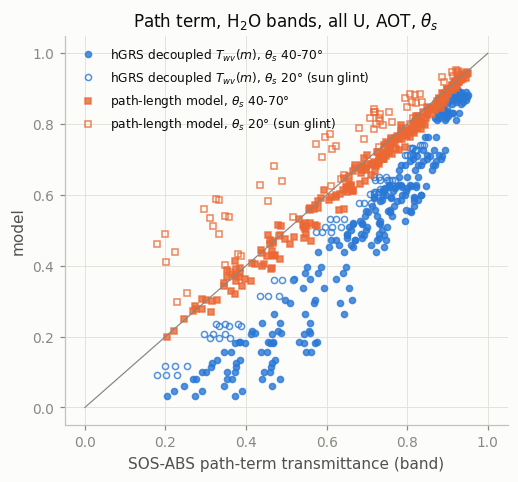

In [8]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
glint = pp.sza == 20
for i, (k, lab) in enumerate([('hgrs_decoupled', 'hGRS decoupled $T_{wv}(m)$'), ('ppld', 'path-length model')]):
    ax.plot(pp.sos_path[~glint], pp[k][~glint], linestyle='none', marker=ct.MARKERS[i], color=ct.COLORS[i], ms=4,
            alpha=0.8, label=lab + ', $\\theta_s$ 40-70°')
    ax.plot(pp.sos_path[glint], pp[k][glint], linestyle='none', marker=ct.MARKERS[i], mfc='none', color=ct.COLORS[i],
            ms=4, alpha=0.8, label=lab + ', $\\theta_s$ 20° (sun glint)')
ax.plot([0, 1], [0, 1], color=ct.MUTED, lw=0.8)
ax.set_xlabel('SOS-ABS path-term transmittance (band)')
ax.set_ylabel('model')
ax.set_title('Path term, H$_2$O bands, all U, AOT, $\\theta_s$')
ax.legend(loc='upper left', fontsize=8)
plt.show()

For solar zenith angles of 40-70°, the path-length model gives the band transmittance of the path term with a median
error between -7 % (931 nm) and 0, and a 90th percentile of the absolute error of 4-6 % in the 720, 820 and 972 nm bands and 8-14 % in
the strong 931-961 nm bands (the residual includes the REPTRAN-CKD difference of section 1; the largest errors are
for AOT 0.05, -5 to -8 %). The decoupled transmittance of hGRS is 17-18 % too low in median in the 720-824 nm bands
and 47-65 % in the 931-961 nm bands.

At $\theta_s$ = 20°, the "path term" of these simulations contains the **sun glint** (relative azimuth 90°, viewing
angle 15.9°), which follows the direct path: the path-length model, made for the scattered light, then overestimates
the transmittance (+30 to +45 % at 931-961 nm for AOT ≤ 0.15). In hGRS the sun glint is a separate term
($R_{dir} BRDF_g$) and keeps the direct-beam transmittance.

## Summary

* The **direct-beam** transmittance of hGRS is right for the **surface term** (water-leaving signal and sun glint), up
  to a REPTRAN-CKD difference of a few percent.
* The **path reflectance** is much less absorbed than the direct beam: $\times$1.1-1.2 in the 720 and 820 nm bands,
  $\times$1.5-2.3 at 940 nm, more for clean atmospheres and large air masses.
* A single transmittance for the whole signal therefore depends on the share of the path reflectance: over black water
  a decoupled model sees 20-42 % of the water vapour column at 941 nm (79-89 % for a water albedo of 0.1).
* The photon path-length model of `radcalnet_oc` gives the path-term transmittance within 4-6 % (8-14 % in the core
  of the 940 nm band) from the same REPTRAN table as hGRS, with coefficients depending on the air mass, the AOT and the
  water vapour; the sun glint must be kept out of it (direct path).

For hGRS this means splitting the gaseous transmittance by term, as the TOA model already splits the signal:

$$
R_{toa} = T_g^{path}\, R_{diff}(\tau_a) + T_g(\bar M) \left[ R_{dir}\, BRDF_g + T^{\downarrow}t^{\uparrow}\pi R_{rs} \right]
$$

with $T_g^{path}$ from the path-length model and $T_g(\bar M)$ the direct-beam transmittance. Notebook 2 uses it for
the water vapour retrieval, notebook 3 for the O2 bands.